# Clusterização de retinografias com um extrator neural leve

## Apresentação dos resultados

Neste notebook eu apresento os resultados do 00_cluster_rd.ipynb. Nele, leio as tabelas, as matrizes e as figuras salvas em results/clustering e explico cada gráfico.

A pergunta que eu quero responder é: quando uma rede leve junta retinografias parecidas, ela junta pela gravidade da retinopatia diabética, pela base de origem (câmera e protocolo) ou pela qualidade da foto? E o que isso muda no desenho do roteador do OIO+?

In [1]:
import warnings
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

Os caminhos e as funções de apoio. A função mostrar exibe uma figura salva pelo notebook principal.

In [2]:
SEMENTE = 42
K_ANALISE = 4
EXTRATORES = ("ImageNet", "Ajustado")
NOMES_GRAUS = {0: "Sem RD", 1: "RD leve", 2: "RD moderada", 3: "RD grave", 4: "RD proliferativa"}
CORES_EXTRATOR = {"ImageNet": "#7A7A7A", "Ajustado": "#1B9E77"}


def localizar_raiz(inicio=None):
    inicio = (inicio or Path.cwd()).resolve()
    for pasta in [inicio, *inicio.parents]:
        if (pasta / "data" / "catalogs").is_dir():
            return pasta
    raise FileNotFoundError(f"Pasta data/catalogs não encontrada acima de {inicio}")


RAIZ = localizar_raiz()
RESULTADOS = RAIZ / "results" / "clustering"
FIGURAS = RESULTADOS / "figuras"


def mostrar(nome, largura=1150):
    display(Image(filename=str(FIGURAS / f"{nome}.png"), width=largura))


def nome_cluster(r):
    return f"C{r + 1}"

In [3]:
IMAGENS = pd.read_csv(RESULTADOS / "imagens_com_cluster.csv")
METRICAS_K = pd.read_csv(RESULTADOS / "metricas_por_k.csv")
DESEMPENHO = pd.read_csv(RESULTADOS / "desempenho_extrator_ajustado_teste.csv", index_col=0)
ESTATISTICAS = {nome: pd.read_csv(RESULTADOS / f"estatisticas_clusters_{nome.lower()}.csv") for nome in EXTRATORES}
print(f"Imagens analisadas: {len(IMAGENS)} ({(IMAGENS['conjunto'] == 'treino').sum()} de treino e {(IMAGENS['conjunto'] == 'teste').sum()} de teste)")

Imagens analisadas: 6281 (4710 de treino e 1571 de teste)


## 0. Fluxo da imagem

Este é o caminho que cada retinografia percorre até chegar ao cluster. Eu recorto a retina, reduzo para 224 × 224, passo pela MobileNetV3-Small e retiro os 1.024 números da camada escondida. Depois normalizo, padronizo e reduzo para 50 números com PCA, e o K-Means decide o cluster. Esse é o mesmo caminho do roteador do OIO+.

<img src="../../docs/assets/fluxo_00_1_presentation_.png" alt="Fluxo da imagem até o cluster" width="1100">

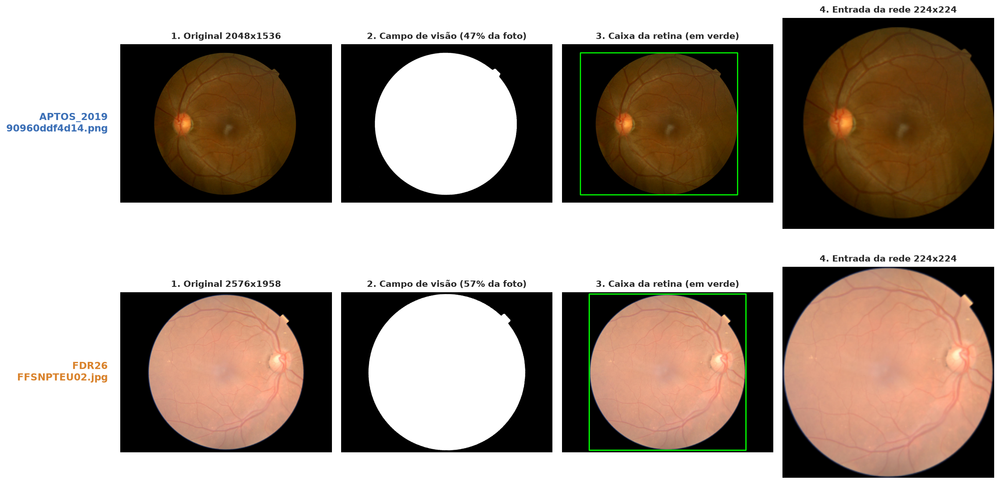

In [4]:
mostrar("03_preprocessamento", 1000)

Fonte: seção 3 do notebook 00_cluster_rd.ipynb, com imagens do APTOS 2019 [3] e do FDR26 [5]. À esquerda está a foto original, e à direita a retina recortada em 224 × 224 que entra na rede.

### O que procurar numa retinografia

Antes de olhar os clusters, eu preciso que o grau de RD faça sentido na imagem. Abaixo estão três retinas reais das bases, com os pontos que eu aponto em cada uma. A numeração está na legenda logo depois da figura.

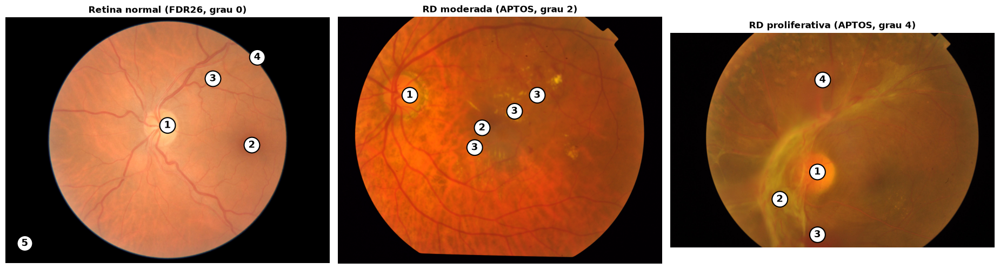

In [5]:
PASTAS_IMAGENS = {"APTOS_2019": RAIZ / "data" / "raw" / "aptos" / "train", "FDR26": RAIZ / "data" / "raw" / "fdr26" / "Fundus_FDR26"}

ANOTACOES = [
    {
        "titulo": "Retina normal (FDR26, grau 0)",
        "arquivo": "L9ZPKR2H01.jpg",
        "base": "FDR26",
        "pontos": [(1, 0.50, 0.44), (2, 0.76, 0.52), (3, 0.64, 0.25), (4, 0.777, 0.163), (5, 0.06, 0.92)],
    },
    {
        "titulo": "RD moderada (APTOS, grau 2)",
        "arquivo": "4dbce359d0e1.png",
        "base": "APTOS_2019",
        "pontos": [(1, 0.222, 0.318), (2, 0.445, 0.45), (3, 0.615, 0.318), (3, 0.545, 0.383), (3, 0.422, 0.53)],
    },
    {
        "titulo": "RD proliferativa (APTOS, grau 4)",
        "arquivo": "20d5fdd450ae.png",
        "base": "APTOS_2019",
        "pontos": [(1, 0.454, 0.648), (2, 0.338, 0.775), (3, 0.454, 0.94), (4, 0.47, 0.22)],
    },
]


def ler_retina(arquivo, base, lado=900):
    bgr = cv2.imread(str(PASTAS_IMAGENS[base] / arquivo))
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    escala = lado / max(rgb.shape[:2])
    return cv2.resize(rgb, (round(rgb.shape[1] * escala), round(rgb.shape[0] * escala)), interpolation=cv2.INTER_AREA)


def marcar_pontos(eixo, pontos):
    for numero, x, y in pontos:
        eixo.annotate(str(numero), (x, 1 - y), xycoords="axes fraction", ha="center", va="center", fontsize=13, fontweight="bold",
                      bbox=dict(boxstyle="circle,pad=0.3", fc="white", ec="black", lw=1.5))


def plotar_retinas_anotadas(anotacoes):
    fig, eixos = plt.subplots(1, len(anotacoes), figsize=(6.2 * len(anotacoes), 5.2))
    for eixo, nota in zip(eixos, anotacoes):
        eixo.imshow(ler_retina(nota["arquivo"], nota["base"]))
        marcar_pontos(eixo, nota["pontos"])
        eixo.set_title(nota["titulo"])
        eixo.axis("off")
    fig.tight_layout()
    return fig


figura = plotar_retinas_anotadas(ANOTACOES)
figura.savefig(FIGURAS / "00_retinas_anotadas.png", bbox_inches="tight")
plt.show()

**Retina normal (FDR26)**

1. Disco óptico: região clara e arredondada, de onde o nervo óptico sai do olho e de onde nascem os vasos principais.
2. Mácula: o centro da visão, a cerca de dois a três diâmetros de disco do disco óptico. É a área escura, sem vasos grossos.
3. Arcada vascular: os vasos grossos saem do disco e contornam a mácula.
4. Entalhe no canto superior direito: marca da câmera, e não da retina. Aparece nas duas bases.
5. Borda preta: fora do campo de visão. O tamanho muda de câmera para câmera, e por isso eu recorto a retina antes da rede.

**RD moderada (APTOS)**

1. Disco óptico, nítido e bem corado.
2. Mácula, a área escura no centro da imagem.
3. Exsudatos duros, os pontos amarelos brilhantes, em grupos ao lado da mácula e em grupos menores mais acima e à direita. Esse padrão torna o caso moderado.

**RD proliferativa (APTOS)**

1. Disco óptico, com tecido esbranquiçado ao redor.
2. Proliferação fibrovascular: faixas claras que saem do disco, sinal de neovasos e fibrose.
3. Hemorragia no bordo inferior, mancha vermelho-escura.
4. Alterações difusas no alto da retina, onde o brilho e a cor se perdem.

### Grau em que aparecem

| O que é | Como aparece | Grau em que surge |
|---|---|---|
| Microaneurisma | Ponto vermelho pequeno e redondo, de poucos pixels. É o primeiro sinal. | 1 em diante |
| Hemorragia intrarretiniana | Mancha vermelha maior que o microaneurisma, em ponto ou em borrão. | 2 em diante |
| Exsudato duro | Depósito amarelo e brilhante, de bordas nítidas, formado por gordura que vazou dos vasos. Costuma se agrupar perto da mácula. | 2 em diante |
| Mancha algodonosa | Mancha branca de bordas difusas, sinal de falta de circulação em um ponto da retina. | 2 em diante |
| Rosário venoso e IRMA | Veias com aspecto de contas e pequenos vasos anômalos dentro da retina. | 3 |
| Neovasos | Vasos novos e frágeis, no disco ou em outras regiões da retina. | 4 |
| Hemorragia pré-retiniana ou vítrea | Mancha vermelho-escura extensa, que pode esconder partes da retina. | 4 |
| Edema macular | Espessamento do centro da retina. É difícil de ver em foto comum e costuma ser confirmado por tomografia (OCT). | Qualquer |

> **Por que importa**
> 
> Os graus leves dependem de pontos de poucos pixels, e a rede recebe a imagem reduzida para 224 pixels. É nessa fronteira, entre leve e moderada, que os resultados mostram a maior dificuldade, e é por isso que o roteador vai apontar essa região como a mais difícil.

Fonte: tabela de achados segundo a escala ICDR [4]; retinografias das bases APTOS 2019 [3] e FDR26 [5].

## 1. As duas bases

Eu uso duas bases. O APTOS 2019 [3] vem de clínicas do Aravind Eye Hospital, na Índia, com várias câmeras e escala ICDR [4]. O FDR26 [5] vem de um hospital universitário de Oujda, no Marrocos, com escala ALFEDIAM, que eu trato como equivalente aproximada da ICDR. Considero RD referável o grau 2 ou mais, o limiar usado nos estudos de rastreamento [6].

### Como a RD aparece na retina

Esta retinografia mostra três sinais clássicos da retinopatia diabética: exsudatos duros (pontos amarelados), microaneurismas e pequenas hemorragias (pontos vermelhos). Nos graus leves esses sinais têm poucos pixels, e é por isso que reduzir para 224 pixels é um limite para a rede.

<img src="../../docs/assets/refs/hao_fundus_dr.png" alt="Retinografia com exsudatos duros, microaneurismas e pequenas hemorragias" width="520">

Fonte: Figura 1, painel A, de Hao et al. [17] (CC BY 4.0).

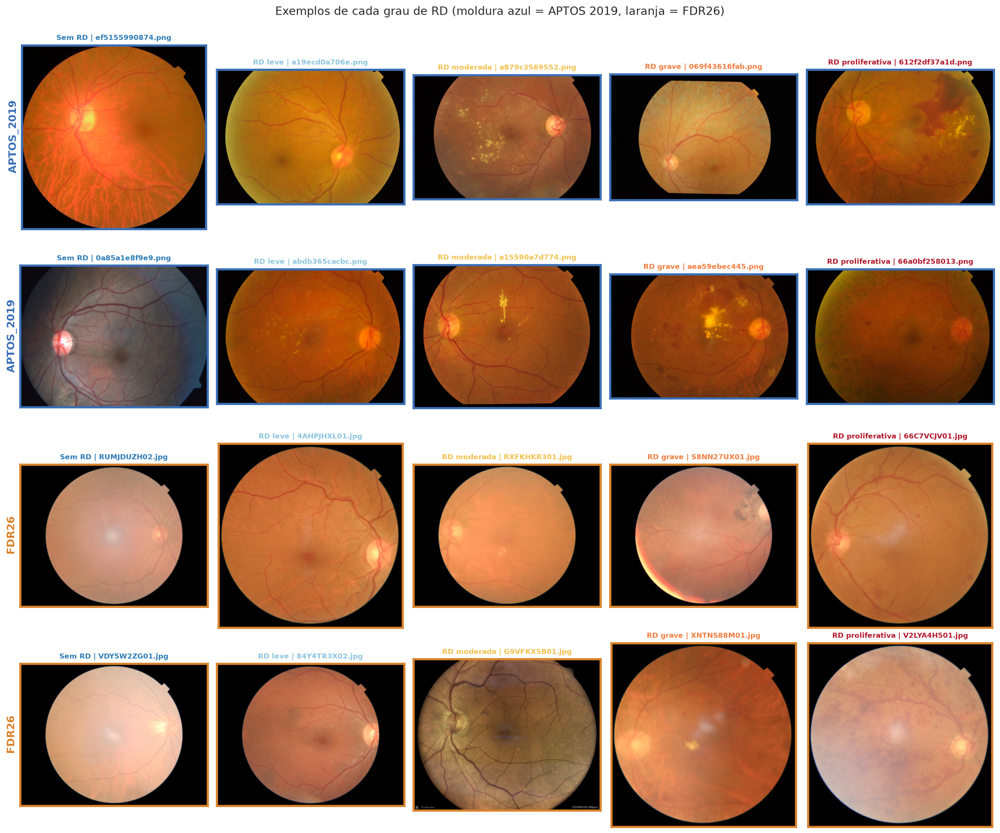

In [6]:
mostrar("02_galeria_por_grau", 1100)

Fonte: seção 2.1 do notebook 00_cluster_rd.ipynb, com imagens do APTOS 2019 [3] e do FDR26 [5]. Duas imagens sorteadas por grau em cada base: o FDR26 é mais claro e rosado, e o APTOS é mais alaranjado e variado.

In [7]:
pd.crosstab(IMAGENS["dataset"], IMAGENS["grau"].map(NOMES_GRAUS), margins=True, margins_name="total")[[*NOMES_GRAUS.values(), "total"]]

grau,Sem RD,RD leve,RD moderada,RD grave,RD proliferativa,total
dataset,,,,,,
APTOS_2019,1796,338,922,177,271,3504
FDR26,485,630,515,592,555,2777
total,2281,968,1437,769,826,6281


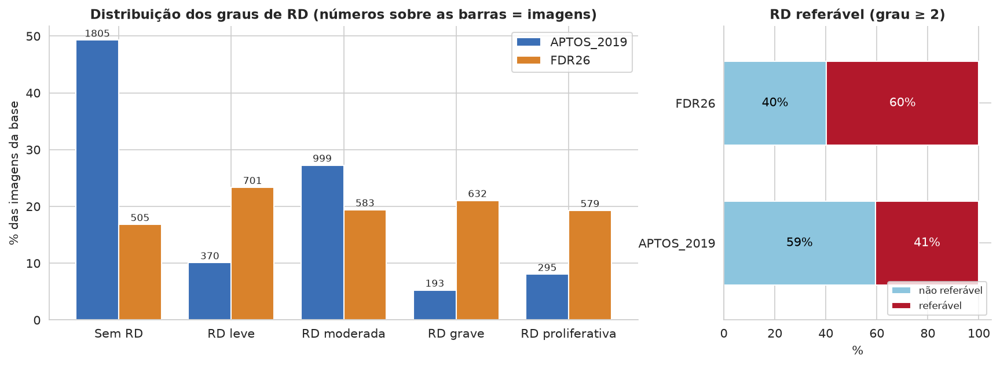

In [8]:
mostrar("01_distribuicao_graus")

À esquerda, cada par de barras é um grau, e a altura é a porcentagem das imagens daquela base que tem o grau (azul é APTOS, laranja é FDR26). À direita, a proporção de RD referável em cada base. O número em cima da barra é a contagem.

As distribuições são quase opostas. Metade do APTOS é sem RD, com poucos casos graves, o perfil de um rastreamento. O FDR26 é equilibrado e tem muito mais RD grave, o perfil de um hospital. A RD referável é cerca de 41% no APTOS e 60% no FDR26.

> **Por que importa**
> 
> Se a base já diz muito sobre o grau, um modelo que reconhece a base ganha acerto sem olhar lesão nenhuma. Toda a análise que vem a seguir mede o tamanho desse risco. No OIO+, com dez bases e três doenças, ele é maior, porque cada base tem a sua prevalência.

## 2. Armadilhas dos dados

### 2.1 Cópias com rótulos diferentes

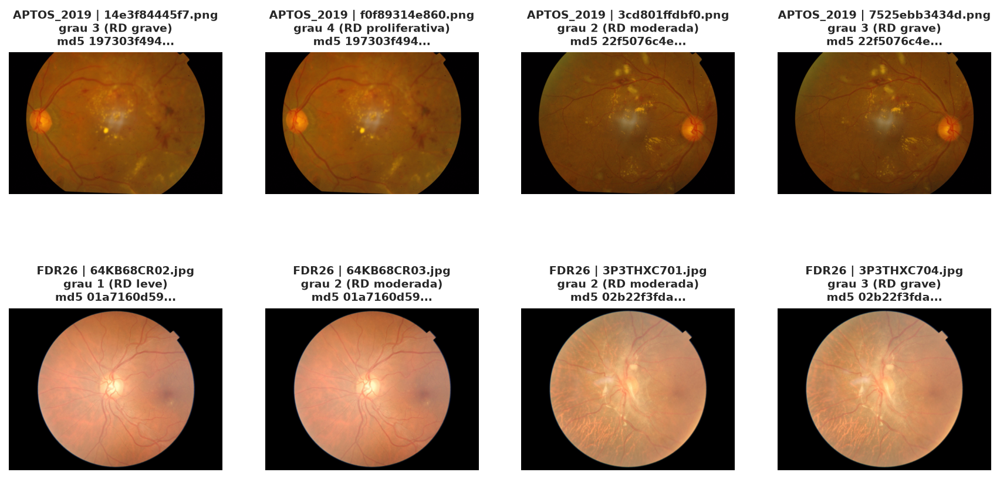

In [9]:
mostrar("04_duplicatas_conflitantes", 950)

Cada par de colunas é o mesmo arquivo, com o mesmo hash MD5, ou seja, conteúdo idêntico pixel a pixel. O título de cada imagem mostra o grau registrado no catálogo.

A mesma foto aparece com dois graus diferentes. No APTOS são 30 grupos de cópias em conflito, o mesmo achado da análise anterior do OIO+. No FDR26 são 62 pares, e em 81 dos 160 pares de cópias as duas versões estão registradas como pacientes diferentes. Eu tirei todas as cópias em conflito e, das cópias sem conflito, mantive só uma: de 6.661 imagens restaram 6.281.

> **Por que importa para o OIO+**
> 
> A deduplicação por hash precisa vir antes de qualquer divisão treino e teste, em todas as bases do projeto. Se não vier, a mesma foto cai dos dois lados e o teste fica otimista.
> 


### 2.2 A resolução da foto adivinha o diagnóstico no APTOS

In [10]:
def doenca_por_resolucao(imagens, base, minimo=50):
    parte = imagens[imagens["dataset"] == base].assign(resolucao=lambda t: t["largura"].astype(str) + " × " + t["altura"].astype(str))
    tabela = parte.groupby("resolucao").agg(imagens=("arquivo", "size"), grau_medio=("grau", "mean"), pct_referavel=("referavel", lambda s: 100 * s.mean()))
    return tabela[tabela["imagens"] >= minimo].sort_values("pct_referavel")


doenca_por_resolucao(IMAGENS, "APTOS_2019")

,imagens,grau_medio,pct_referavel
resolucao,,,
2048 × 1536,351,0.000,0.000
819 × 614,287,0.031,0.348
1050 × 1050,972,0.151,5.350
2588 × 1958,533,1.311,48.405
2416 × 1736,585,1.938,61.368
4288 × 2848,52,2.462,65.385
1844 × 1226,61,2.426,78.689
3388 × 2588,141,2.390,90.780
3216 × 2136,374,2.297,96.257


Cada linha é uma resolução de foto (largura × altura, em pixels) com pelo menos 50 imagens. A última coluna é a porcentagem de RD referável entre as fotos daquela resolução.

As fotos de 2.048 × 1.536 são todas sem RD, e as de 3.216 × 2.136 são quase todas referáveis. A resolução identifica a câmera ou a clínica, e cada clínica enviou pacientes de gravidade diferente. O V de Cramér entre resolução e RD referável é 0,74.

> **Por que importa**
> 
> Isso é um atalho [7]: um modelo pode acertar o diagnóstico reconhecendo a câmera. Mais adiante eu mostro que esse atalho deixa marca mesmo depois do recorte e da redução para 224 pixels.

### O mesmo problema em outras áreas

O exemplo da terceira coluna é o nosso caso: uma rede que reconhece pneumonia olhando a marca do hospital, e não o pulmão, e por isso falha em exames de hospitais novos. No APTOS, a resolução faz o papel da marca do hospital.

<img src="../../docs/assets/refs/geirhos_fig1.png" alt="Exemplos de aprendizado por atalho: legenda de imagens, objetos, pneumonia e perguntas" width="1100">

Fonte: Figura 1 de Geirhos et al. [7] (CC BY 4.0).

## 3. As bases diferem na aquisição, não na doença

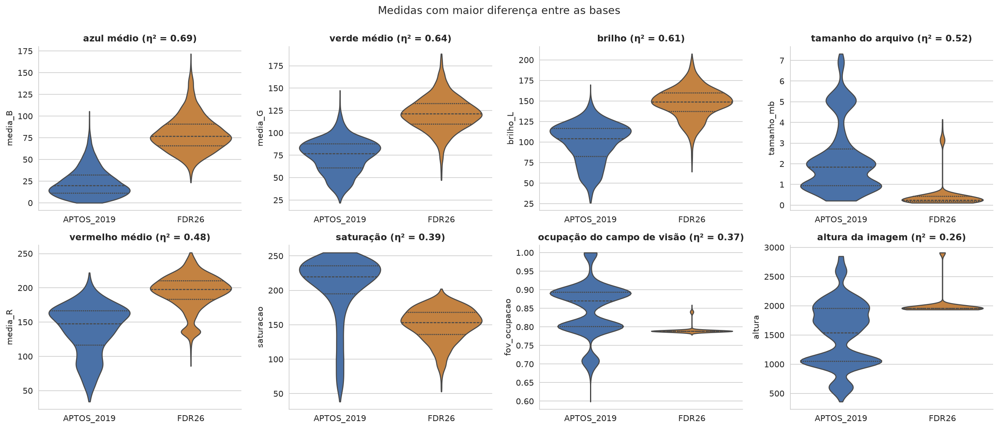

In [11]:
mostrar("04_medidas_por_base")

Cada painel é uma medida calculada nos pixels da retina. O violino mostra a distribuição em cada base: onde ele é largo há muitas imagens com aquele valor. As linhas tracejadas internas são os quartis. O η² no título é a fração da variação da medida explicada pela base, de 0 a 1. Acima de 0,14 o efeito é considerado grande [8].

As oito medidas com maior diferença são de cor, brilho, tamanho de arquivo e enquadramento. O azul médio quase não se sobrepõe entre as bases (η² = 0,69). O FDR26 é estreito em tamanho de arquivo e enquadramento, sinal de uma câmera só. O APTOS tem vários picos, um por câmera. As medidas ligadas a lesões e vasos, que não aparecem aqui, quase não diferem entre as bases (η² < 0,01).

Há uma forte diferença de domínio entre as bases. As imagens diferem bastante em cor, brilho, resolução e enquadramento, independentemente de qualquer doença.

> **Por que importa**
> 
> O que separa as bases é a aquisição. Um extrator que agrupe por cor e enquadramento vai agrupar por base, e um roteador construído sobre ele vai rotear por câmera, e não por doença.

## 4. O extrator leve e a matriz de características

Eu uso a MobileNetV3-Small em duas versões com a mesma arquitetura. A versão ImageNet nunca viu uma retinografia. A versão Ajustado parte da ImageNet e eu a treinei por 15 épocas para prever os 5 graus, só com imagens de treino, guardando os pesos da época com melhor kappa ponderado na validação. Em ambas, o embedding é a saída da camada escondida de 1.024 neurônios.

In [12]:
DESEMPENHO.round(3)

,imagens,QWK (5 graus),acurácia (5 graus),AUC RD referável,acurácia RD referável
APTOS_2019,876.0,0.882,0.821,0.978,0.920
FDR26,695.0,0.757,0.542,0.914,0.836
as duas bases,1571.0,0.844,0.698,0.953,0.883


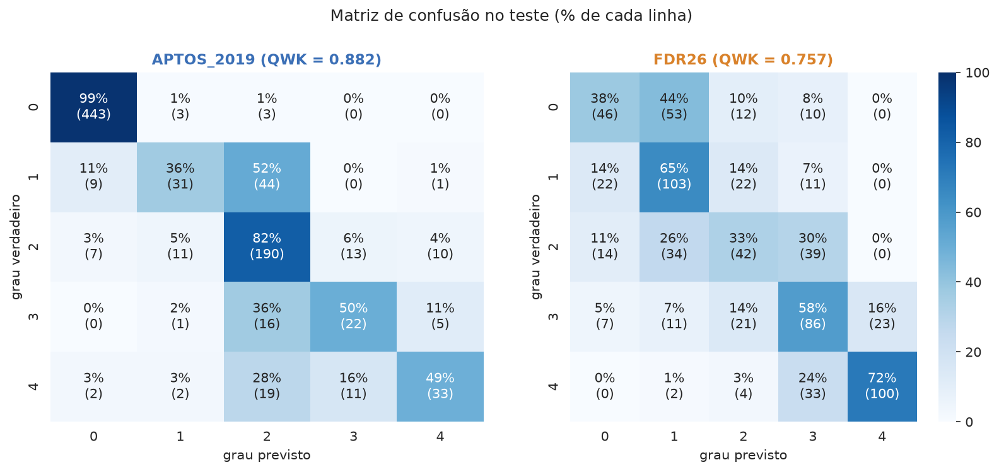

In [13]:
mostrar("06_matriz_confusao", 950)

Cada linha é o grau verdadeiro e cada coluna, o grau previsto pela rede ajustada, no teste. A célula mostra a porcentagem da linha e, entre parênteses, a contagem. Uma rede perfeita teria 100% na diagonal.

No teste, o kappa ponderado é 0,88 no APTOS e 0,76 no FDR26, e a AUC de RD referável é 0,98 e 0,91. No APTOS, quase todo olho sem RD é reconhecido, mas a RD leve vira moderada em metade dos casos. No FDR26, os erros se concentram entre os graus 0, 1 e 2.

> **Por que importa**
> 
> O desempenho mostra que a camada escondida aprendeu RD, e portanto o embedding tem informação clínica. Mostra também onde a rede tem dificuldade: na fronteira entre leve e moderada, sobretudo no FDR26. É exatamente onde o roteador vai encontrar a região difícil, na seção 10.

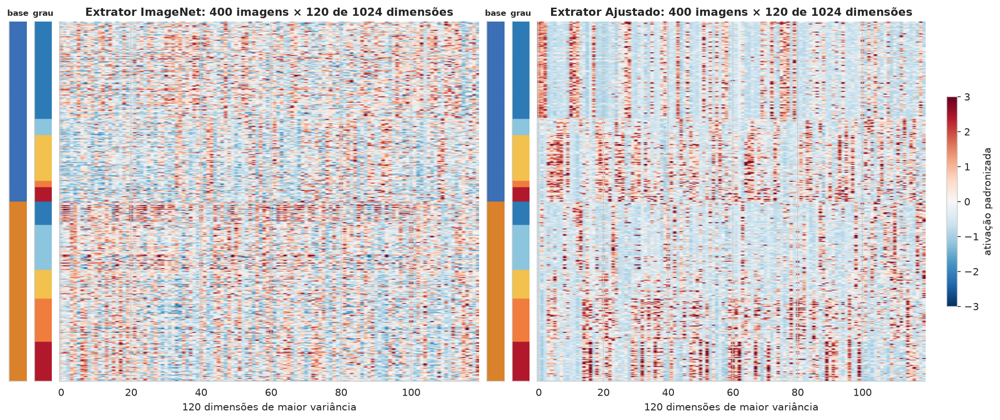

In [14]:
mostrar("07_matriz_caracteristicas")

Aqui eu desenhei a matriz de características como imagem. Cada linha é uma imagem (400 sorteadas, ordenadas por base e grau), cada coluna é uma das 120 dimensões que mais variam, e a cor é o valor padronizado da ativação. As faixas à esquerda indicam a base e o grau de cada linha. Blocos horizontais que mudam junto com as faixas indicam que o embedding codifica aquela informação.

Na matriz do ImageNet há um único corte visível, na troca de base, e nenhum ao longo dos graus. Na matriz do Ajustado os padrões mudam com o grau dentro de cada base, mas cada base continua com o seu próprio conjunto de dimensões ativas.

> **Por que importa**
> 
> Antes de qualquer K-Means, já dá para prever o resultado: o ImageNet vai separar bases, e o Ajustado vai separar base e gravidade ao mesmo tempo.

## 5. Quantos grupos?

Este é o gráfico principal para escolher K. A linha cinza é o extrator ImageNet e a verde, o Ajustado. A linha pontilhada vertical marca K = 4.

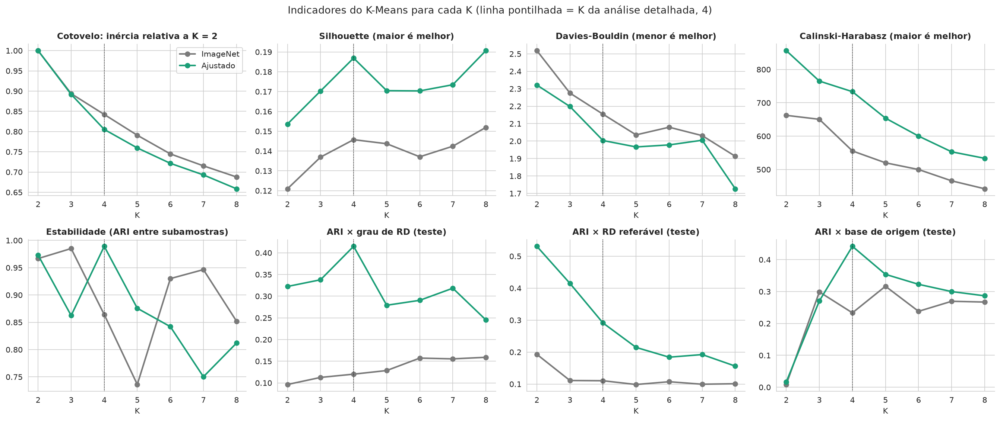

In [15]:
mostrar("08_metricas_por_k")

A linha de cima tem os indicadores internos, que não olham nenhum rótulo e foram medidos no treino:

- Cotovelo: a inércia (soma das distâncias ao quadrado até o centro) relativa a K = 2. Ela sempre cai quando K sobe, e procura-se uma dobra.
- Silhouette [9]: de −1 a 1, maior é melhor. Diz se cada imagem está mais perto do próprio grupo do que do vizinho.
- Davies-Bouldin: menor é melhor. Mede sobreposição entre grupos.
- Calinski-Harabasz: maior é melhor. Compara a dispersão entre grupos com a dispersão dentro deles.

A linha de baixo tem a estabilidade (ARI entre K-Means feitos em subamostras de 80%) e três indicadores externos, medidos no teste: o ARI [10] dos clusters contra o grau, contra a RD referável e contra a base. O ARI vale 1 quando as partições são idênticas e perto de 0 quando a coincidência é por acaso.

1. A silhouette fica entre 0,12 e 0,19. Os grupos não são ilhas isoladas, e sim regiões de uma nuvem contínua. O cotovelo não tem dobra clara. Os indicadores internos sozinhos não escolhem K.
2. O Ajustado é melhor que o ImageNet em silhouette, Davies-Bouldin e Calinski-Harabasz em todos os K, e muito melhor nos externos. O ARI contra o grau chega a 0,42 com K = 4, contra 0,12 do ImageNet.
3. Com K = 2, o ARI contra a base é quase zero nos dois extratores, e o ARI contra a RD referável do Ajustado é o maior (0,53). A primeira divisão do Ajustado é de gravidade e atravessa as duas bases. A partir de K = 3 a base aparece.
4. Em K = 4, o Ajustado tem a maior estabilidade (0,99) e o maior ARI contra o grau, e a silhouette é praticamente igual à de K = 8.

> **Ressalva**
> 
> Eu escolhi K = 4 olhando também o ARI contra o grau no teste. É uma escolha informada pelos rótulos, e não uma descoberta cega.

> **Por que importa para o OIO+**
> 
> No desenho do roteador, K não é só um número de grupos, é o número de especialistas. Esse gráfico é a ferramenta que eu uso para escolhê-lo: estabilidade alta garante que a região de uma imagem não muda quando os dados mudam um pouco, e o ARI contra a base avisa quando as regiões estão virando regiões de câmera.

In [16]:
(
    METRICAS_K[METRICAS_K["extrator"] == "Ajustado"]
    .set_index("k")[["silhouette", "davies_bouldin", "estabilidade", "menor_cluster_%", "ARI_grau", "ARI_referavel", "ARI_base"]]
    .round(3)
)

,silhouette,davies_bouldin,estabilidade,menor_cluster_%,ARI_grau,ARI_referavel,ARI_base
k,,,,,,,
2,0.154,2.321,0.973,48.344,0.322,0.531,0.017
3,0.170,2.198,0.862,24.671,0.338,0.415,0.271
4,0.187,2.003,0.989,22.845,0.415,0.291,0.442
5,0.170,1.966,0.876,14.544,0.279,0.215,0.354
6,0.170,1.978,0.842,10.340,0.290,0.184,0.323
7,0.173,2.005,0.750,6.518,0.318,0.192,0.300
8,0.191,1.727,0.812,2.654,0.245,0.156,0.287


A tabela traz os números do extrator Ajustado. A coluna menor_cluster_% explica por que eu descartei K = 8: com K = 8, o menor cluster tem menos de 3% das imagens e a estabilidade cai para 0,81. Para um roteador, uma região muito pequena significa um especialista treinado com pouca gente.

## 6. Os grupos dependem do algoritmo?

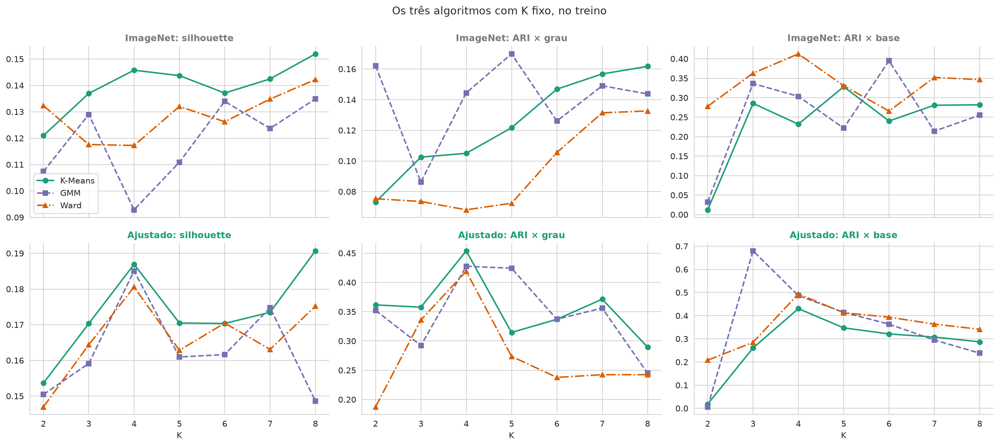

In [17]:
mostrar("09_comparacao_algoritmos")

Linha de cima, ImageNet. Linha de baixo, Ajustado. Cada painel compara três algoritmos que recebem K: K-Means (verde), mistura de gaussianas (roxo, tracejado) e Ward (laranja). Os valores são do treino.

No Ajustado, as três curvas de ARI contra o grau têm o pico em K = 4, e com K = 4 os três algoritmos concordam entre si (ARI de 0,88 entre GMM e K-Means e de 0,84 entre Ward e K-Means). No ImageNet, as curvas se cruzam e oscilam sem um K preferido.

> **Por que importa**
> 
> Se algoritmos com hipóteses diferentes (grupos redondos, elípticos ou hierárquicos) chegam aos mesmos grupos, a estrutura está nos dados e não no método. O K-Means continua como escolha para o roteador porque é o único dos quatro que classifica uma imagem nova de forma direta, pelo centro mais próximo.

## 7. O mapa UMAP

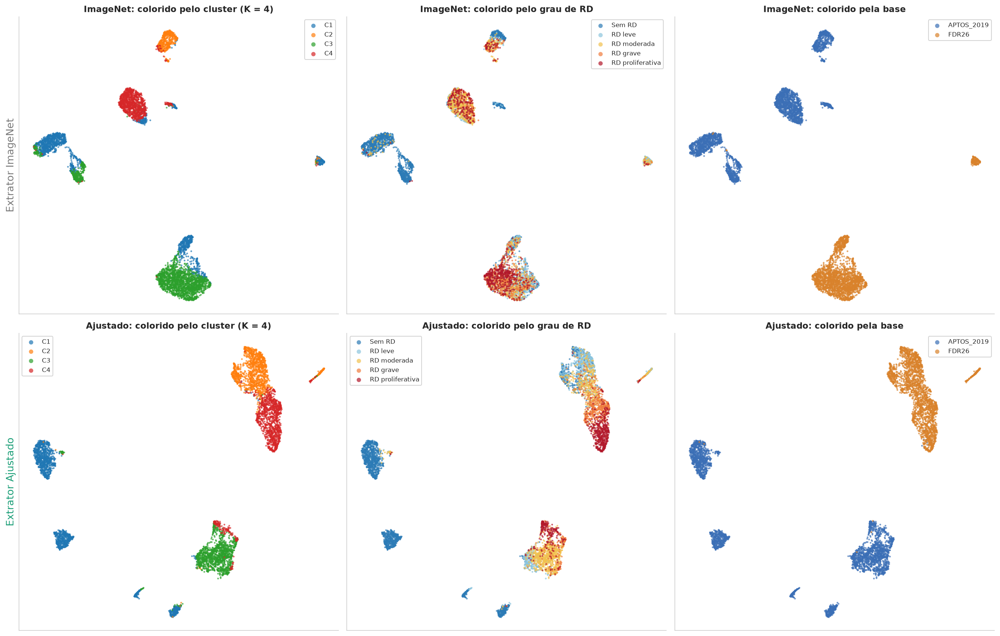

In [18]:
mostrar("10_umap_cluster_grau_base")

O UMAP [11] projeta as 50 dimensões em um plano, tentando manter perto o que está perto. Cada ponto é uma imagem. O mesmo mapa é pintado de três formas: pelo cluster do K-Means (esquerda), pelo grau de RD (meio) e pela base (direita). Eu leio o mapa comparando o painel da esquerda com os outros dois: se ele se parece com o da base, os clusters são de aquisição. Se se parece com o do grau, são de gravidade. Eu não leio distâncias entre ilhas ao pé da letra, porque o agrupamento é feito nas 50 dimensões, e não no mapa.

ImageNet (linha de cima): ilhas que correspondem às bases e, dentro do APTOS, a câmeras. Dentro de cada ilha, os graus estão misturados (painel do meio). Os clusters seguem as ilhas.

Ajustado (linha de baixo): cada base continua em uma região, mas dentro dela há ordem. No FDR26 aparece um gradiente contínuo, do azul (sem RD) no alto até o vermelho escuro (proliferativa) embaixo. No APTOS, os olhos sem RD formam ilhas próprias, e os doentes se juntam em outra. Os quatro clusters cortam exatamente isso: cada base em menos grave e mais grave.

> **Por que importa**
> 
> O gradiente do FDR26 mostra que a gravidade é contínua no embedding. Por isso a silhouette é baixa: cortar um contínuo em pedaços sempre deixa imagens perto da fronteira. Para o roteador, isso quer dizer que imagens de fronteira podem cair em um especialista ou no vizinho, e os dois precisam saber lidar com elas.

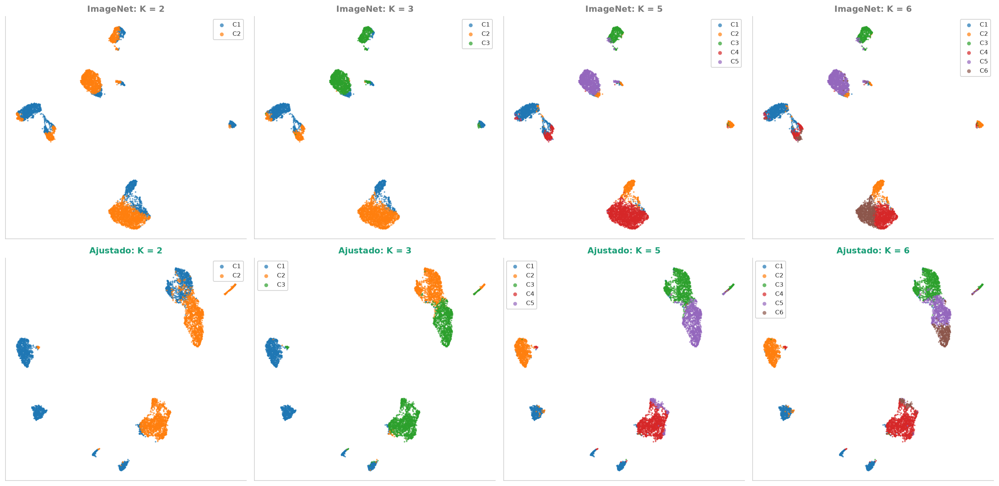

In [19]:
mostrar("10_umap_varios_k")

O mesmo mapa, pintado pelos clusters de K = 2, 3, 5 e 6. A sequência mostra qual região se separa primeiro quando K cresce.

No Ajustado, K = 2 divide menos grave de mais grave atravessando as duas bases (um cluster com 9% de RD referável, o outro com 86%). Com K = 3, o APTOS sem RD e o FDR26 leve ganham clusters próprios. Com K = 5 e 6, o gradiente do FDR26 é fatiado em faixas. No ImageNet, K maior só subdivide câmeras.

> **Por que importa**
> 
> A ordem em que as regiões aparecem é a ordem de importância das diferenças para a rede. No Ajustado, a primeira diferença é clínica, e a base vem em segundo lugar. No ImageNet, a primeira é técnica.

## 8. O que há dentro de cada cluster

Eu numerei os clusters pelo grau médio no treino: C1 é o de menor grau e C4, o de maior.

In [20]:
ESTATISTICAS["Ajustado"].set_index("cluster")[["imagens", "% do total", "silhouette média", "grau médio", "% referável", "% FDR26", "% do treino", "% do teste"]].round(2)

,imagens,% do total,silhouette média,grau médio,% referável,% FDR26,% do treino,% do teste
cluster,,,,,,,,
C1,1829,29.12,0.27,0.04,1.26,1.26,28.94,29.66
C2,1524,24.26,0.12,1.05,28.87,98.69,24.03,24.95
C3,1516,24.14,0.19,2.06,78.56,0.79,24.18,24.00
C4,1412,22.48,0.15,3.29,97.59,87.68,22.85,21.39


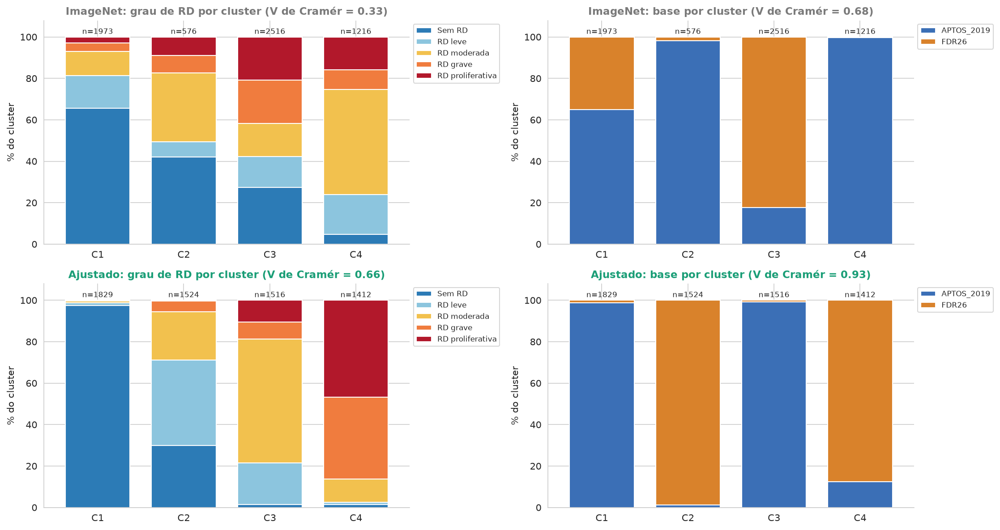

In [21]:
mostrar("11_composicao_clusters")

Cada barra é um cluster e soma 100%. À esquerda, as cores são os graus de RD, do azul (sem RD) ao vermelho escuro (proliferativa). À direita, as cores são as bases. O V de Cramér no título mede a associação entre cluster e variável, de 0 a 1 [12]. Em cima de cada barra está o número de imagens.

No Ajustado (linha de baixo), cada cluster é praticamente de uma base só (V = 0,93) e tem um perfil de gravidade claro (V = 0,66 com o grau):

| Cluster | Base | Conteúdo | Nome curto |
|---|---|---|---|
| C1 | APTOS | 97% sem RD | APTOS saudável |
| C2 | FDR26 | graus 0 e 1 na maioria, 29% referável | FDR26 leve |
| C3 | APTOS | 60% moderada, 79% referável | APTOS doente |
| C4 | FDR26 | graus 3 e 4 na maioria, 98% referável | FDR26 grave |

No ImageNet (linha de cima), a base também domina (V = 0,68), mas o grau quase não aparece (V = 0,33): C3 junta quase todo o FDR26, com todos os graus misturados.

> **Por que importa**
> 
> A partição é o cruzamento de duas perguntas: de onde veio a imagem e quão grave ela é. A rede aprendeu a doença sem esquecer a origem. No teste, que nem a rede nem o K-Means viram, os valores são parecidos (V de 0,94 com a base e de 0,75 com a RD referável), o que afasta a ideia de que os clusters só refletem memorização do treino.

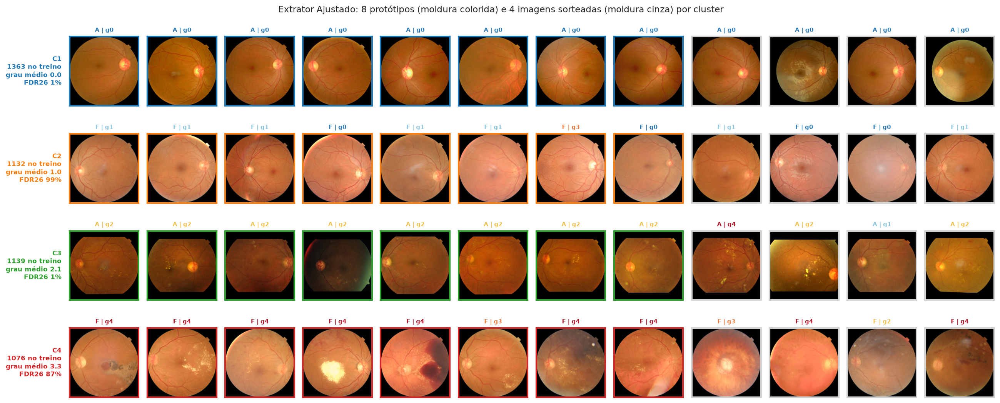

In [22]:
mostrar("10_mosaico_ajustado")

Cada linha é um cluster do Ajustado. As 8 primeiras imagens são as mais próximas do centro, os protótipos. As 4 últimas são sorteadas, para mostrar o cluster no dia a dia. O título traz a base (A ou F) e o grau.

C1 são retinas alaranjadas e limpas do APTOS. C2 são retinas claras do FDR26 quase sem lesão visível. C3 são retinas do APTOS com exsudatos amarelos espalhados. C4 são retinas do FDR26 com lesões extensas, hemorragias e fibrose. Os protótipos são coerentes do ponto de vista clínico.

> **Por que importa**
> 
> O mosaico é o jeito de auditar um cluster com o olho de um oftalmologista. No OIO+, ele serve para dar nome a cada região antes de entregar a região a um especialista.

## 9. Que medidas da imagem explicam os clusters

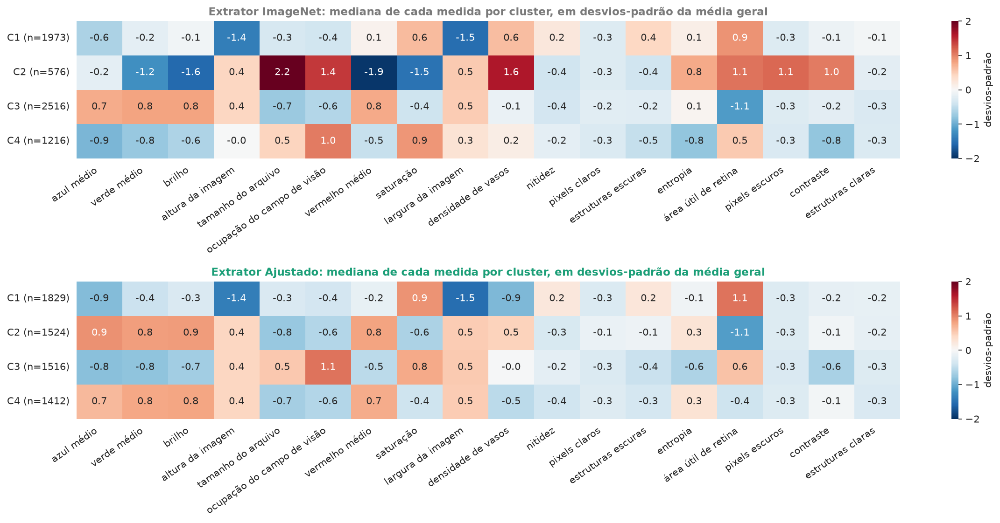

In [23]:
mostrar("11_heatmap_medidas")

Cada linha é um cluster e cada coluna, uma medida da imagem. O número é a mediana do cluster em desvios-padrão em relação à média de todas as imagens: vermelho está acima da média e azul, abaixo. As colunas estão ordenadas da medida que mais separa os clusters (esquerda) para a que menos separa (direita), pelo η² do teste de Kruskal-Wallis.

No Ajustado, as medidas que mais separam os clusters são cor e brilho, porque cada cluster é de uma base. O dado mais revelador é a altura e a largura da imagem: C1 (APTOS saudável) tem fotos 1,4 desvio abaixo da média, e C3 (APTOS doente), fotos maiores. É o atalho de resolução da seção 2 aparecendo dentro dos clusters. No ImageNet, C2 tem os maiores desvios do mapa: arquivo grande, campo de visão cortado, pouco vermelho e pouco brilho, características de uma câmera. A densidade de vasos só existe no FDR26, e por isso só é informativa em C2 e C4.

> **Por que importa**
> 
> Este é o teste de sanidade do roteador. Se as colunas mais fortes de uma região são de câmera, a região é de câmera. Um especialista atribuído a ela vai aprender a câmera junto com a doença.

## 10. O que isso significa para o OIO+

O desenho do OIO+ tem três peças: um modelo leve que funciona como roteador, uma matriz da última camada escondida que vai para um K-Means com K = 1, 2, 3, 4…, e um conjunto de modelos L do qual cada região recebe o melhor, L*. É o esquema de agrupar e selecionar de Kuncheva [13], parente da mistura de especialistas [14].

| Peça do OIO+ | O que já existe no notebook principal |
|---|---|
| Modelo leve que funciona como roteador | MobileNetV3-Small ajustada, com pesos salvos em results/clustering/cache |
| Matriz da última camada escondida (N × d) | matriz_caracteristicas_ajustado.npy, 6.281 × 1.024 |
| K-Means com K = 1, 2, 3, 4… | K de 2 a 8 com indicadores, estabilidade e escolha justificada |
| Uma regra para mandar uma imagem nova a uma região | o centro mais próximo do K-Means, com a mesma normalização e o mesmo PCA do treino |
| Checagem de que as regiões não são de câmera | ARI e V de Cramér contra a base, heatmap de medidas e mosaicos |
| Divisão treino e teste sem vazamento | divisão por paciente e remoção de cópias por hash |

Faltava o conjunto L e a escolha do L*. Nas células abaixo eu faço uma versão pequena desse passo, para mostrar o mecanismo funcionando nos dados reais.

### 10.1 Um roteador em miniatura

O alvo é a RD referável. Eu monto o conjunto L com cinco classificadores simples, todos treinados sobre a mesma matriz Z de 50 dimensões, com as imagens de ajuste. Para cada região, o L* é o modelo com maior acurácia nas imagens de validação daquela região, e a avaliação é no teste. Também calculo o oráculo, que escolhe o L* olhando o próprio teste: ele é o teto do mecanismo, e não um resultado válido.

In [24]:
@dataclass
class Espaco:
    Z: np.ndarray
    treino: np.ndarray
    ajuste: np.ndarray
    validacao: np.ndarray
    teste: np.ndarray
    y: np.ndarray
    graus: np.ndarray


def montar_espaco(nome, imagens, componentes=50):
    E = np.load(RESULTADOS / f"matriz_caracteristicas_{nome.lower()}.npy")
    treino = (imagens["conjunto"] == "treino").to_numpy()
    preparo = make_pipeline(Normalizer(), StandardScaler(), PCA(componentes, random_state=SEMENTE)).fit(E[treino])
    return Espaco(
        Z=preparo.transform(E),
        treino=treino,
        ajuste=(imagens["papel_no_ajuste"] == "ajuste").to_numpy(),
        validacao=(imagens["papel_no_ajuste"] == "validação").to_numpy(),
        teste=(imagens["conjunto"] == "teste").to_numpy(),
        y=imagens["referavel"].to_numpy(),
        graus=imagens["grau"].to_numpy(),
    )


def regioes(espaco, k):
    if k == 1:
        return np.zeros(len(espaco.Z), dtype=int), espaco.Z[espaco.treino].mean(0, keepdims=True)
    modelo = KMeans(k, n_init=10, random_state=SEMENTE).fit(espaco.Z[espaco.treino])
    ordem = np.argsort([espaco.graus[espaco.treino][modelo.labels_ == r].mean() for r in range(k)])
    novo_nome = np.empty(k, dtype=int)
    novo_nome[ordem] = np.arange(k)
    return novo_nome[modelo.predict(espaco.Z)], modelo.cluster_centers_[ordem]


ESPACOS = {nome: montar_espaco(nome, IMAGENS) for nome in EXTRATORES}
rotulos_k4, _ = regioes(ESPACOS["Ajustado"], K_ANALISE)
coincide = (pd.Series(rotulos_k4).map(nome_cluster).to_numpy() == IMAGENS["cluster_ajustado"].to_numpy()).mean()
print(f"Regiões com K = 4 iguais aos clusters do notebook principal em {100 * coincide:.1f}% das imagens")

Regiões com K = 4 iguais aos clusters do notebook principal em 100.0% das imagens


Eu refiz o preparo da matriz e o K-Means com as mesmas sementes do notebook principal. A conferência mostra que as regiões com K = 4 são exatamente os clusters C1 a C4 já analisados.

In [25]:
def criar_pool():
    return {
        "Regressão logística": LogisticRegression(C=0.1, max_iter=2000),
        "kNN (k = 25)": KNeighborsClassifier(25),
        "Floresta aleatória": RandomForestClassifier(300, min_samples_leaf=5, random_state=SEMENTE, n_jobs=-1),
        "LDA": LinearDiscriminantAnalysis(),
        "Naive Bayes": GaussianNB(),
    }


def treinar_pool(espaco):
    return {nome: modelo.fit(espaco.Z[espaco.ajuste], espaco.y[espaco.ajuste]) for nome, modelo in criar_pool().items()}


def prever_pool(pool, espaco):
    return {nome: modelo.predict(espaco.Z) for nome, modelo in pool.items()}


def escolher_l_estrela(previsoes, rotulos, mascara, y):
    escolhas = {}
    for r in np.unique(rotulos):
        alvo = mascara & (rotulos == r)
        escolhas[r] = max(previsoes, key=lambda nome: accuracy_score(y[alvo], previsoes[nome][alvo]))
    return escolhas


def maioria_por_regiao(rotulos, mascara, y):
    return {r: int(round(y[mascara & (rotulos == r)].mean())) for r in np.unique(rotulos)}


def rotear(previsoes, rotulos, escolhas):
    saida = np.empty(len(rotulos), dtype=int)
    for r, nome in escolhas.items():
        saida[rotulos == r] = previsoes[nome][rotulos == r]
    return saida


POOLS = {nome: treinar_pool(ESPACOS[nome]) for nome in EXTRATORES}
PREVISOES = {nome: prever_pool(POOLS[nome], ESPACOS[nome]) for nome in EXTRATORES}

In [26]:
def avaliar_roteador(espaco, previsoes, ks=(1, 2, 3, 4, 5, 6, 8)):
    linhas = []
    teste, y = espaco.teste, espaco.y
    for k in ks:
        rotulos, _ = regioes(espaco, k)
        escolhas = escolher_l_estrela(previsoes, rotulos, espaco.validacao, y)
        oraculo = escolher_l_estrela(previsoes, rotulos, teste, y)
        maioria = maioria_por_regiao(rotulos, espaco.ajuste, y)
        linhas.append({
            "K": k,
            "roteador": accuracy_score(y[teste], rotear(previsoes, rotulos, escolhas)[teste]),
            "oráculo": accuracy_score(y[teste], rotear(previsoes, rotulos, oraculo)[teste]),
            "só a região": accuracy_score(y[teste], np.array([maioria[r] for r in rotulos])[teste]),
            "modelos distintos escolhidos": len(set(escolhas.values())),
        })
    return pd.DataFrame(linhas)


ROTEADOR_K = pd.concat({nome: avaliar_roteador(ESPACOS[nome], PREVISOES[nome]) for nome in EXTRATORES}, names=["extrator"]).reset_index(level=0)
ROTEADOR_K.set_index(["extrator", "K"]).round(3)

roteador  oráculo  só a região  modelos distintos escolhidos
extrator K                                                              
ImageNet 1     0.844    0.854        0.518                             1
         2     0.855    0.855        0.720                             2
         3     0.849    0.857        0.687                             2
         4     0.851    0.857        0.684                             4
         5     0.852    0.861        0.696                             4
         6     0.850    0.861        0.729                             4
         8     0.854    0.864        0.729                             3
Ajustado 1     0.884    0.891        0.518                             1
         2     0.885    0.894        0.864                             2
         3     0.890    0.894        0.861                             3
         4     0.890    0.898        0.856                             3
         5     0.891    0.899        0.856                             3
         6     0.885    0.899        0.867                             4
         8     0.886    0.901        0.863                             4

In [27]:
def ganho_com_intervalo(espaco, previsoes, k, repeticoes=2000):
    rng = np.random.default_rng(SEMENTE)
    acertos = {}
    for kk in (1, k):
        rotulos, _ = regioes(espaco, kk)
        escolhas = escolher_l_estrela(previsoes, rotulos, espaco.validacao, espaco.y)
        acertos[kk] = (rotear(previsoes, rotulos, escolhas) == espaco.y)[espaco.teste]
    diferenca = acertos[k].astype(float) - acertos[1].astype(float)
    amostras = rng.integers(0, len(diferenca), size=(repeticoes, len(diferenca)))
    medias = diferenca[amostras].mean(1)
    return pd.Series({"ganho (pontos percentuais)": 100 * diferenca.mean(), "IC 95% inferior": 100 * np.percentile(medias, 2.5), "IC 95% superior": 100 * np.percentile(medias, 97.5)})


pd.DataFrame({nome: ganho_com_intervalo(ESPACOS[nome], PREVISOES[nome], K_ANALISE) for nome in EXTRATORES}).T.round(2)

,ganho (pontos percentuais),IC 95% inferior,IC 95% superior
ImageNet,0.70,-0.32,1.78
Ajustado,0.64,-0.06,1.34


Na primeira tabela, cada linha é um K. K = 1 é o sistema sem roteador: um único modelo, o melhor do conjunto na validação. A coluna roteador é a acurácia no teste quando cada região usa o seu L*. Oráculo é o teto, com o L* escolhido no próprio teste. Só a região é a acurácia de responder, para toda imagem, a classe mais comum da sua região, sem modelo nenhum. Com K = 1 ela é só a classe mais comum da base inteira (52%), e por isso fica fora do gráfico abaixo. A segunda tabela mostra o ganho do roteador com K = 4 sobre o modelo único, com intervalo de confiança de 95% por reamostragem pareada das imagens de teste.

Três coisas.

Primeiro, o mecanismo funciona de ponta a ponta: imagem nova, região pelo centro mais próximo, modelo escolhido para a região, previsão. Com o extrator Ajustado, o roteador fica entre 88% e 89% de acurácia em todos os K, e regiões diferentes escolhem modelos diferentes.

Segundo, o ganho sobre o modelo único é pequeno e o intervalo de confiança inclui o zero. Com cinco modelos parecidos, treinados na mesma matriz, não há especialista de verdade para escolher: todos erram nas mesmas imagens. O oráculo mostra que, mesmo escolhendo com o gabarito, o teto fica menos de 1 ponto acima do roteador.

Terceiro, a coluna só a região chega a cerca de 86% no Ajustado com K = 4, contra 68% no ImageNet. A região do Ajustado, sozinha, já é quase um classificador, porque os clusters são de gravidade. As regiões do ImageNet, que são de câmera, dizem bem menos sobre a doença. Esse é o lado bom e o lado perigoso: parte desse acerto vem de saber a base, como a seção 2 mostrou.

> **Por que importa para o OIO+**
> 
> O roteador só vale a pena se o conjunto L tiver modelos realmente diferentes: arquiteturas diferentes, resoluções diferentes, modelos treinados em bases ou doenças diferentes. Com um conjunto homogêneo, a seleção por região não tem o que selecionar.


### 10.2 Onde está a região difícil

In [28]:
def desempenho_por_regiao(espaco, pool, previsoes, k):
    rotulos, _ = regioes(espaco, k)
    probabilidade = pool["Regressão logística"].predict_proba(espaco.Z)[:, 1]
    maioria = maioria_por_regiao(rotulos, espaco.ajuste, espaco.y)
    escolhas = escolher_l_estrela(previsoes, rotulos, espaco.validacao, espaco.y)
    linhas = []
    for r in range(k):
        alvo = espaco.teste & (rotulos == r)
        y = espaco.y[alvo]
        linha = {
            "região": nome_cluster(r),
            "imagens de teste": int(alvo.sum()),
            "% referável": 100 * y.mean(),
            "acurácia só da região": accuracy_score(y, np.full(len(y), maioria[r])),
            "AUC dentro da região": roc_auc_score(y, probabilidade[alvo]) if 0 < y.mean() < 1 else np.nan,
            "L* escolhido": escolhas[r],
        }
        linha.update({f"acurácia {nome}": accuracy_score(y, previsoes[nome][alvo]) for nome in previsoes})
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("região")


POR_REGIAO = desempenho_por_regiao(ESPACOS["Ajustado"], POOLS["Ajustado"], PREVISOES["Ajustado"], K_ANALISE)
POR_REGIAO.round(3)

,imagens de teste,% referável,acurácia só da região,AUC dentro da região,L* escolhido,acurácia Regressão logística,acurácia kNN (k = 25),acurácia Floresta aleatória,acurácia LDA,acurácia Naive Bayes
região,,,,,,,,,,
C1,466,2.790,0.972,0.985,Regressão logística,0.979,0.972,0.972,0.972,0.974
C2,392,31.378,0.686,0.747,LDA,0.763,0.737,0.747,0.768,0.714
C3,377,78.515,0.785,0.875,Floresta aleatória,0.841,0.865,0.833,0.844,0.814
C4,336,97.024,0.970,0.810,Regressão logística,0.973,0.973,0.976,0.976,0.973


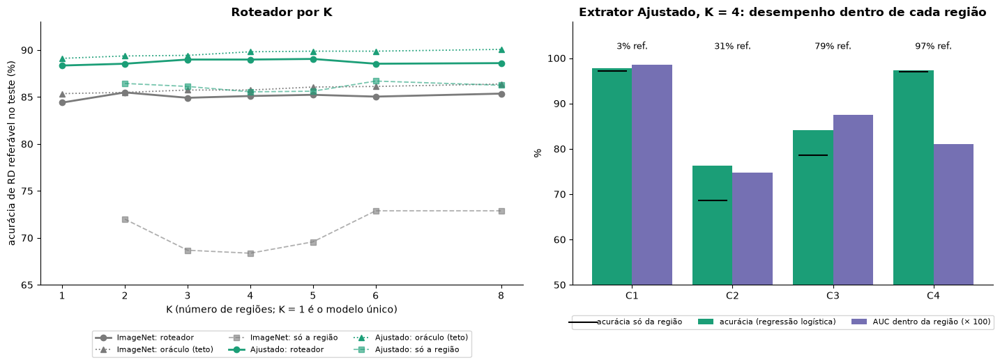

In [29]:
def plotar_roteador(roteador_k, por_regiao):
    fig, eixos = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
    for nome in EXTRATORES:
        parte = roteador_k[roteador_k["extrator"] == nome]
        cor = CORES_EXTRATOR[nome]
        eixos[0].plot(parte["K"], 100 * parte["roteador"], "o-", color=cor, lw=2, label=f"{nome}: roteador")
        eixos[0].plot(parte["K"], 100 * parte["oráculo"], "^:", color=cor, lw=1.3, label=f"{nome}: oráculo (teto)")
        regiao = parte[parte["K"] > 1]
        eixos[0].plot(regiao["K"], 100 * regiao["só a região"], "s--", color=cor, lw=1.3, alpha=0.6, label=f"{nome}: só a região")
    eixos[0].set_xlabel("K (número de regiões; K = 1 é o modelo único)")
    eixos[0].set_ylabel("acurácia de RD referável no teste (%)")
    eixos[0].set_title("Roteador por K")
    eixos[0].set_xticks(sorted(roteador_k["K"].unique()))
    eixos[0].set_ylim(65, 93)
    eixos[0].legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
    posicoes = np.arange(len(por_regiao))
    eixos[1].bar(posicoes - 0.2, 100 * por_regiao["acurácia Regressão logística"], 0.4, color="#1B9E77", label="acurácia (regressão logística)")
    eixos[1].bar(posicoes + 0.2, 100 * por_regiao["AUC dentro da região"], 0.4, color="#7570B3", label="AUC dentro da região (× 100)")
    eixos[1].scatter(posicoes - 0.2, 100 * por_regiao["acurácia só da região"], marker="_", s=900, color="black", zorder=3, label="acurácia só da região")
    for x, (_, linha) in zip(posicoes, por_regiao.iterrows()):
        eixos[1].text(x, 102, f"{linha['% referável']:.0f}% ref.", ha="center", fontsize=9)
    eixos[1].set_xticks(posicoes, por_regiao.index)
    eixos[1].set_ylim(50, 108)
    eixos[1].set_ylabel("%")
    eixos[1].set_title("Extrator Ajustado, K = 4: desempenho dentro de cada região")
    eixos[1].legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    fig.tight_layout()
    return fig


figura = plotar_roteador(ROTEADOR_K, POR_REGIAO)
figura.savefig(FIGURAS / "12_roteador.png", bbox_inches="tight")
plt.show()

À esquerda, a acurácia no teste para cada K, com uma cor por extrator. A linha cheia é o roteador, a pontilhada é o teto do oráculo e a tracejada é a resposta só pela região. O eixo vertical começa em 65%. À direita, as quatro regiões do Ajustado com K = 4. A barra verde é a acurácia da regressão logística dentro da região, o traço preto é a acurácia de responder a classe mais comum da região, e a barra roxa é a AUC dentro da região, isto é, o quanto o modelo ordena bem os casos daquela região entre si. Em cima, a proporção de RD referável na região.

O extrator Ajustado fica cerca de 4 pontos acima do ImageNet em qualquer K. A escolha do extrator pesa mais que a escolha de K.

As regiões têm dificuldades muito diferentes. Em C1 (APTOS saudável) e C4 (FDR26 grave), a acurácia passa de 97%, mas quase empata com a resposta pela maioria, porque essas regiões são quase de uma classe só. Em C3 (APTOS doente), o modelo ganha alguns pontos sobre a maioria. Em C2 (FDR26 leve) está o problema: a acurácia cai para cerca de 76% e a AUC dentro da região é a menor das quatro, perto de 0,75. É a fronteira entre RD leve e moderada no FDR26, a mesma que a matriz de confusão da seção 4 apontou.

> **Por que importa para o OIO+**
> 
> Este é o uso mais concreto do que eu fiz. O roteador não serve só para ganhar acurácia média: ele diz onde o sistema falha e, portanto, onde vale investir um especialista. No nosso caso, a prioridade seria um modelo para C2, com imagens em resolução maior, porque a diferença entre RD leve e moderada está em microaneurismas e pequenas hemorragias, que somem a 224 pixels. É o que Oakden-Rayner et al. chamam de estratificação oculta: subgrupos em que o desempenho global esconde uma falha [15].
> 


### 10.3 Como uma imagem nova é roteada

In [30]:
def rota_de_imagens(espaco, previsoes, imagens, k, por_regiao=1):
    rotulos, centros = regioes(espaco, k)
    escolhas = escolher_l_estrela(previsoes, rotulos, espaco.validacao, espaco.y)
    linhas = []
    for r in range(k):
        indice = np.flatnonzero(espaco.teste & (rotulos == r))[:por_regiao]
        for i in indice:
            distancias = np.linalg.norm(centros - espaco.Z[i], axis=1)
            linha = {"arquivo": imagens.loc[i, "arquivo"], "base": imagens.loc[i, "dataset"], "grau verdadeiro": int(imagens.loc[i, "grau"])}
            linha.update({f"distância a {nome_cluster(j)}": d for j, d in enumerate(distancias)})
            linha.update({"região": nome_cluster(int(np.argmin(distancias))), "L*": escolhas[r], "previsto referável": int(previsoes[escolhas[r]][i]), "referável de fato": int(espaco.y[i])})
            linhas.append(linha)
    return pd.DataFrame(linhas)


rota_de_imagens(ESPACOS["Ajustado"], PREVISOES["Ajustado"], IMAGENS, K_ANALISE).round(1)

,arquivo,base,grau verdadeiro,distância a C1,distância a C2,distância a C3,distância a C4,região,L*,previsto referável,referável de fato
0,04efb1a284cc.png,APTOS_2019,0,13.8,28.5,32.2,33.6,C1,Regressão logística,0,0
1,22098b1fe461.png,APTOS_2019,1,27.6,22.3,23.6,32.3,C2,LDA,0,0
2,0024cdab0c1e.png,APTOS_2019,1,30.1,28.4,25.2,32.9,C3,Floresta aleatória,0,0
3,0981195eb9fb.png,APTOS_2019,4,35.3,32.8,29.7,26.5,C4,Regressão logística,1,1


Cada linha é uma imagem de teste, a primeira de cada região. A imagem passa pela rede, vira um vetor de 50 números e é comparada com os quatro centros. A menor distância decide a região, e a região decide o modelo. É assim que o roteador trataria uma imagem que chega de uma clínica.

Na segunda linha, uma imagem do APTOS com RD leve, as distâncias a C2 (22,3) e a C3 (23,6) quase empatam: é uma imagem de fronteira, que caiu na região do FDR26 leve. A diferença entre a menor distância e a segunda menor diz o quanto a imagem está no meio de uma região ou perto da fronteira. Uma imagem longe de todos os centros, de uma câmera nunca vista, por exemplo, deveria ser sinalizada em vez de roteada sem aviso. Esse controle é um dos próximos passos que eu proponho.

### 10.4 Como levar isso para as dez bases do OIO+

1. Reaproveitar o pipeline como está. As funções de catálogo, deduplicação por hash, divisão por paciente, extração da camada escondida e indicadores por K não dependem de RD, e funcionam para glaucoma e DMRI trocando o catálogo.
2. Medir o efeito de base antes de rotear. Com dez bases, o ARI e o V de Cramér contra a base devem ser os primeiros números olhados. Se as regiões forem de câmera, normalizar cor e resolução antes do extrator, ou ajustar o extrator com um objetivo que penalize reconhecer a base.
3. Montar um conjunto L heterogêneo. Os resultados da seção 10.1 mostram que modelos parecidos não dão ao roteador o que escolher. O conjunto deve variar arquitetura, resolução de entrada e dados de treino.
4. Escolher L* com validação separada, nunca com o teste. A diferença entre roteador e oráculo é o otimismo de escolher com o gabarito, e ela cresce quando as regiões são pequenas.
5. Usar o desempenho por região como relatório. A tabela da seção 10.2 é o formato natural para mostrar ao grupo onde o sistema é confiável e onde não é.
6. Comparar com um modelo de fundação de retina, como o RETFound [16], para saber quanto do resultado depende de o extrator ser leve.

### Próximo passo: um extrator treinado só em retinas

O RETFound foi pré-treinado de forma auto-supervisionada com retinografias e cortes de OCT, e depois ajustado para diagnóstico de RD, glaucoma e outras doenças. Comparar o nosso extrator leve com ele mede quanto do resultado vem do extrator.

<img src="../../docs/assets/refs/retfound_fig1.png" alt="Visão geral do RETFound: pré-treino auto-supervisionado e ajuste para tarefas clínicas" width="1000">

Fonte: Figura 1 de Zhou et al. [16] (CC BY 4.0).

## 11. Fechamento

1. As duas bases diferem na aquisição, e não na doença. Cor, brilho, resolução e compressão separam APTOS e FDR26 com efeito grande.
2. Sem ajuste, o extrator leve agrupa por câmera e base. O ARI dos clusters contra o grau é 0,12.
3. Com ajuste, os clusters ganham sentido clínico. Com K = 4, são estáveis (0,99), concordam entre algoritmos e têm ARI de 0,42 contra o grau no teste.
4. Mesmo ajustado, o extrator não esquece a base. Os quatro clusters são APTOS saudável, APTOS doente, FDR26 leve e FDR26 grave.
5. O APTOS tem um atalho de resolução, e ele aparece dentro dos clusters.
6. Para o OIO+, o mecanismo do roteador já funciona sobre a matriz gerada. O ganho depende de um conjunto L heterogêneo, e o maior valor imediato está em apontar a região difícil, que aqui é o FDR26 leve.

Limitações principais: duas bases apenas, sem identificação de câmera; equivalência ALFEDIAM e ICDR aproximada; K = 4 escolhido olhando também o ARI no teste; imagens de 224 pixels perdem microaneurismas; o roteador em miniatura usa um conjunto L pequeno e homogêneo, e serve para mostrar o mecanismo, não para estimar o ganho final.

## Reserva para perguntas

Figuras de apoio, que eu uso só se surgir uma pergunta.

### Por que a silhouette média é baixa?

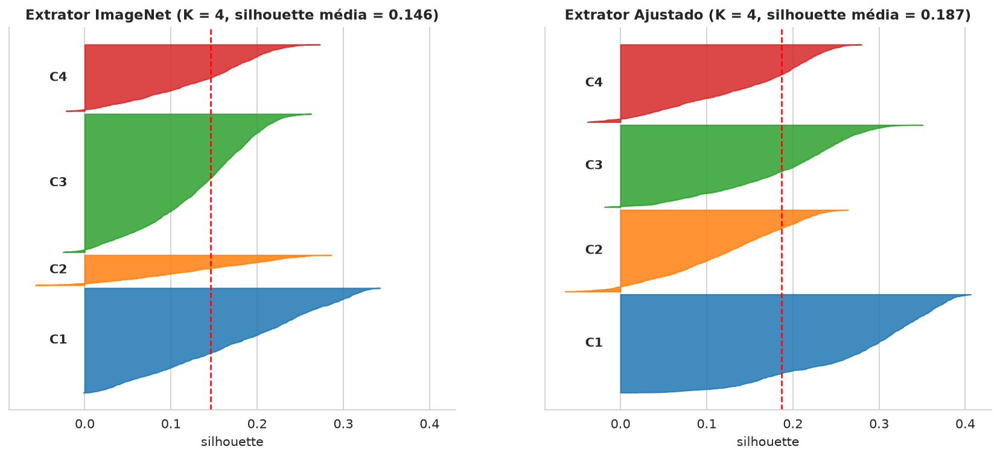

In [31]:
mostrar("08_diagrama_silhouette", 1000)

Cada barra horizontal é uma imagem de treino, e o comprimento é a sua silhouette. A linha vermelha é a média. No Ajustado, C1 é o cluster mais bem definido, com quase nenhuma barra negativa. As barras negativas, imagens mais perto de outro cluster, aparecem sobretudo em C2 e C4, os clusters do FDR26, onde os graus formam um contínuo. Só 2,7% das imagens do Ajustado têm silhouette negativa: os clusters são regiões de uma nuvem contínua, e não grupos misturados.

### Por que 50 componentes no PCA?

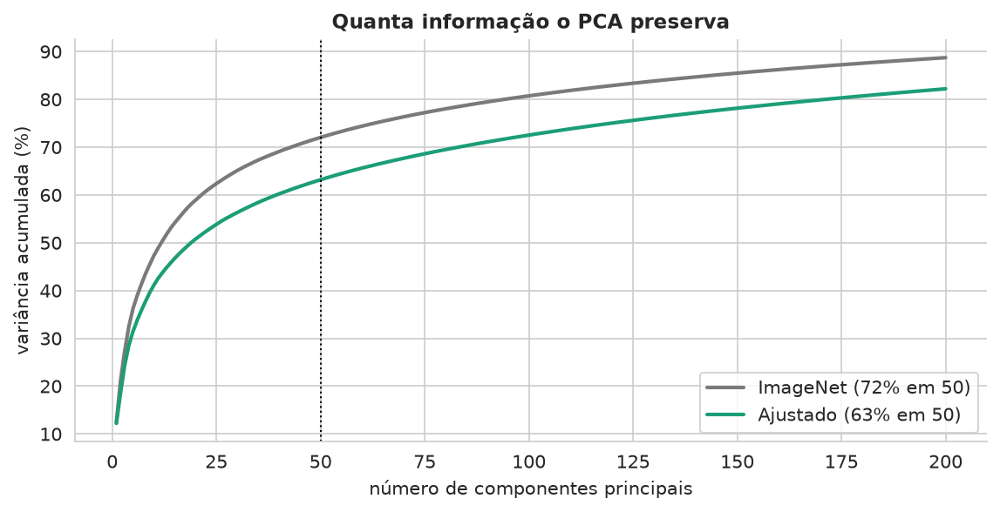

In [32]:
mostrar("07_variancia_pca", 750)

A curva mostra a variância acumulada em função do número de componentes. Com 50 componentes ficam 72% da variância no ImageNet e 63% no Ajustado. Os primeiros componentes, que carregam base e grau, estão incluídos, e o resto é sobretudo ruído, que atrapalharia as distâncias do K-Means.

### Como são os clusters do extrator sem ajuste?

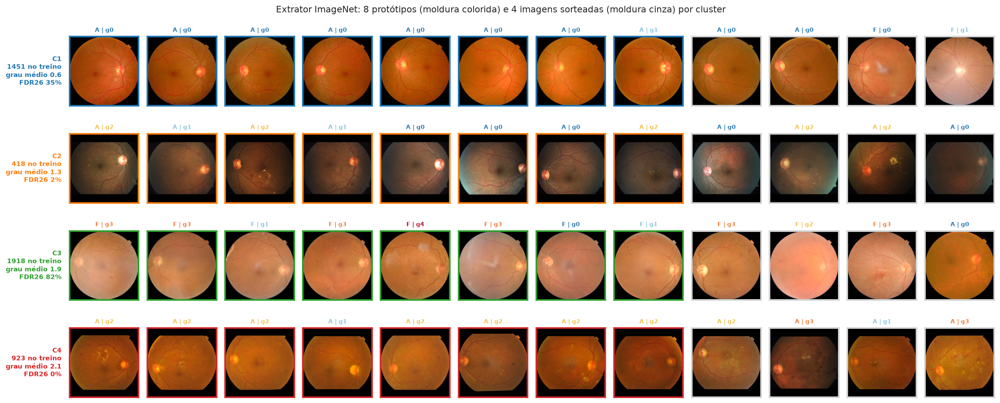

In [33]:
mostrar("10_mosaico_imagenet")

Os clusters do ImageNet são descritos pela aparência da foto. C2 reúne fotos escuras e esverdeadas do APTOS, com o círculo cortado, de uma câmera específica, misturando graus 0 a 2. C3 reúne as fotos claras do FDR26, com todos os graus.

### A rede ajustada sobreajustou?

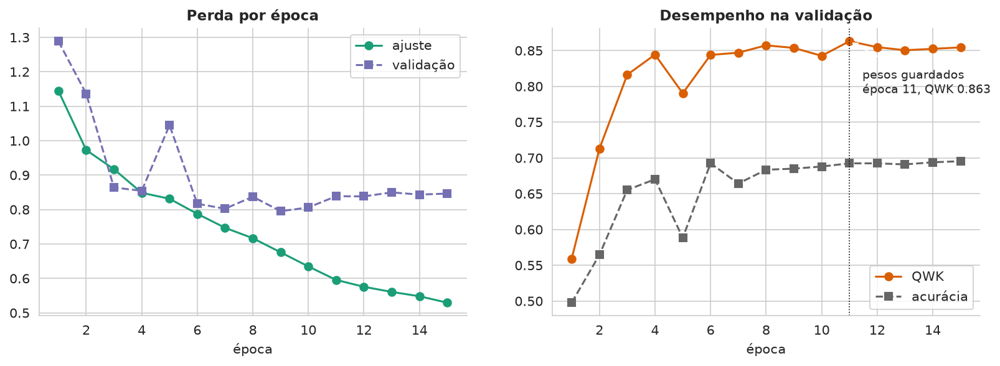

In [34]:
mostrar("06_historico_ajuste", 900)

A perda de ajuste continua caindo enquanto a de validação estabiliza a partir da época 6, um começo de sobreajuste. Os pesos guardados são os da época com maior kappa na validação (época 11), e o teste não participou dessa escolha.

## Referências

1. Howard A, Sandler M, Chen B, Wang W, Chen LC, Tan M, et al. Searching for MobileNetV3. In: 2019 IEEE/CVF International Conference on Computer Vision (ICCV). Seoul: IEEE; 2019. p. 1314-24. doi:10.1109/ICCV.2019.00140
2. Lloyd S. Least squares quantization in PCM. IEEE Trans Inf Theory. 1982;28(2):129-37. doi:10.1109/TIT.1982.1056489
3. Karthik, Maggie, Dane S. APTOS 2019 Blindness Detection [Internet]. Kaggle; 2019 [citado 2026 nov 5]. Disponível em: https://www.kaggle.com/competitions/aptos2019-blindness-detection
4. Wilkinson CP, Ferris FL 3rd, Klein RE, Lee PP, Agardh CD, Davis M, et al. Proposed international clinical diabetic retinopathy and diabetic macular edema disease severity scales. Ophthalmology. 2003;110(9):1677-82. doi:10.1016/S0161-6420(03)00475-5
5. Lamti S, Kerzazi N, Sekhsoukh R, Guechati A. FDR26: a dataset of fundus images for diabetic retinopathy classification and vessels segmentation [Internet]. Zenodo; 2026 [citado 2026 nov 5]. Versão 3. doi:10.5281/zenodo.23101200
6. Gulshan V, Peng L, Coram M, Stumpe MC, Wu D, Narayanaswamy A, et al. Development and validation of a deep learning algorithm for detection of diabetic retinopathy in retinal fundus photographs. JAMA. 2016;316(22):2402-10. doi:10.1001/jama.2016.17216
7. Geirhos R, Jacobsen JH, Michaelis C, Zemel R, Brendel W, Bethge M, et al. Shortcut learning in deep neural networks. Nat Mach Intell. 2020;2(11):665-73. doi:10.1038/s42256-020-00257-z
8. Cohen J. Statistical power analysis for the behavioral sciences. 2nd ed. Hillsdale: Lawrence Erlbaum Associates; 1988.
9. Rousseeuw PJ. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. J Comput Appl Math. 1987;20:53-65. doi:10.1016/0377-0427(87)90125-7
10. Hubert L, Arabie P. Comparing partitions. J Classif. 1985;2(1):193-218. doi:10.1007/BF01908075
11. McInnes L, Healy J, Saul N, Großberger L. UMAP: Uniform Manifold Approximation and Projection. J Open Source Softw. 2018;3(29):861. doi:10.21105/joss.00861
12. Cramér H. Mathematical methods of statistics. Princeton: Princeton University Press; 1946.
13. Kuncheva LI. Clustering-and-selection model for classifier combination. In: KES'2000. Fourth International Conference on Knowledge-Based Intelligent Engineering Systems and Allied Technologies. Brighton: IEEE; 2000. v. 1, p. 185-8. doi:10.1109/KES.2000.885788
14. Jacobs RA, Jordan MI, Nowlan SJ, Hinton GE. Adaptive mixtures of local experts. Neural Comput. 1991;3(1):79-87. doi:10.1162/neco.1991.3.1.79
15. Oakden-Rayner L, Dunnmon J, Carneiro G, Ré C. Hidden stratification causes clinically meaningful failures in machine learning for medical imaging. In: Proceedings of the ACM Conference on Health, Inference, and Learning (CHIL). New York: ACM; 2020. p. 151-9. doi:10.1145/3368555.3384468
16. Zhou Y, Chia MA, Wagner SK, Ayhan MS, Williamson DJ, Struyven RR, et al. A foundation model for generalizable disease detection from retinal images. Nature. 2023;622(7981):156-63. doi:10.1038/s41586-023-06555-x
17. Hao S, Liu C, Li N, Wu Y, Li D, Gao Q, et al. Clinical evaluation of AI-assisted screening for diabetic retinopathy in rural areas of midwest China. PLoS One. 2022;17(10):e0275983. doi:10.1371/journal.pone.0275983